In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("../../datasets/a_regression_car_price/car_prices_dataset.csv")
df.head()

,Unnamed: 0,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,New_Price,Price
0,0,Maruti Wagon R LXI CNG,Mumbai,2010,72000,CNG,Manual,First,26.6 km/kg,998 CC,58.16 bhp,5.0,NaN,1.75
1,1,Hyundai Creta 1.6 CRDi SX Option,Pune,2015,41000,Diesel,Manual,First,19.67 kmpl,1582 CC,126.2 bhp,5.0,NaN,12.50
2,2,Honda Jazz V,Chennai,2011,46000,Petrol,Manual,First,18.2 kmpl,1199 CC,88.7 bhp,5.0,8.61 Lakh,4.50
3,3,Maruti Ertiga VDI,Chennai,2012,87000,Diesel,Manual,First,20.77 kmpl,1248 CC,88.76 bhp,7.0,NaN,6.00
4,4,Audi A4 New 2.0 TDI Multitronic,Coimbatore,2013,40670,Diesel,Automatic,Second,15.2 kmpl,1968 CC,140.8 bhp,5.0,NaN,17.74


## EDA

In [3]:
df.shape

(6019, 14)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6019 entries, 0 to 6018
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Unnamed: 0         6019 non-null   int64  
 1   Name               6019 non-null   object 
 2   Location           6019 non-null   object 
 3   Year               6019 non-null   int64  
 4   Kilometers_Driven  6019 non-null   int64  
 5   Fuel_Type          6019 non-null   object 
 6   Transmission       6019 non-null   object 
 7   Owner_Type         6019 non-null   object 
 8   Mileage            6017 non-null   object 
 9   Engine             5983 non-null   object 
 10  Power              5983 non-null   object 
 11  Seats              5977 non-null   float64
 12  New_Price          824 non-null    object 
 13  Price              6019 non-null   float64
dtypes: float64(2), int64(3), object(9)
memory usage: 658.5+ KB


In [5]:
df.describe()

,Unnamed: 0,Year,Kilometers_Driven,Seats,Price
count,6019.000000,6019.000000,6.019000e+03,5977.000000,6019.000000
mean,3009.000000,2013.358199,5.873838e+04,5.278735,9.479468
std,1737.679967,3.269742,9.126884e+04,0.808840,11.187917
min,0.000000,1998.000000,1.710000e+02,0.000000,0.440000
25%,1504.500000,2011.000000,3.400000e+04,5.000000,3.500000
50%,3009.000000,2014.000000,5.300000e+04,5.000000,5.640000
75%,4513.500000,2016.000000,7.300000e+04,5.000000,9.950000
max,6018.000000,2019.000000,6.500000e+06,10.000000,160.000000


In [6]:
df.describe(include='O')

,Name,Location,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,New_Price
count,6019,6019,6019,6019,6019,6017,5983,5983,824
unique,1876,11,5,2,4,442,146,372,540
top,Mahindra XUV500 W8 2WD,Mumbai,Diesel,Manual,First,18.9 kmpl,1197 CC,74 bhp,95.13 Lakh
freq,49,790,3205,4299,4929,172,606,235,6


In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.isna().sum()

Unnamed: 0              0
Name                    0
Location                0
Year                    0
Kilometers_Driven       0
Fuel_Type               0
Transmission            0
Owner_Type              0
Mileage                 2
Engine                 36
Power                  36
Seats                  42
New_Price            5195
Price                   0
dtype: int64

In [9]:
df.isnull().mean()[df.isnull().mean() > 0]  * 100

Mileage       0.033228
Engine        0.598106
Power         0.598106
Seats         0.697790
New_Price    86.310018
dtype: float64

In [10]:
%pip install missingno

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


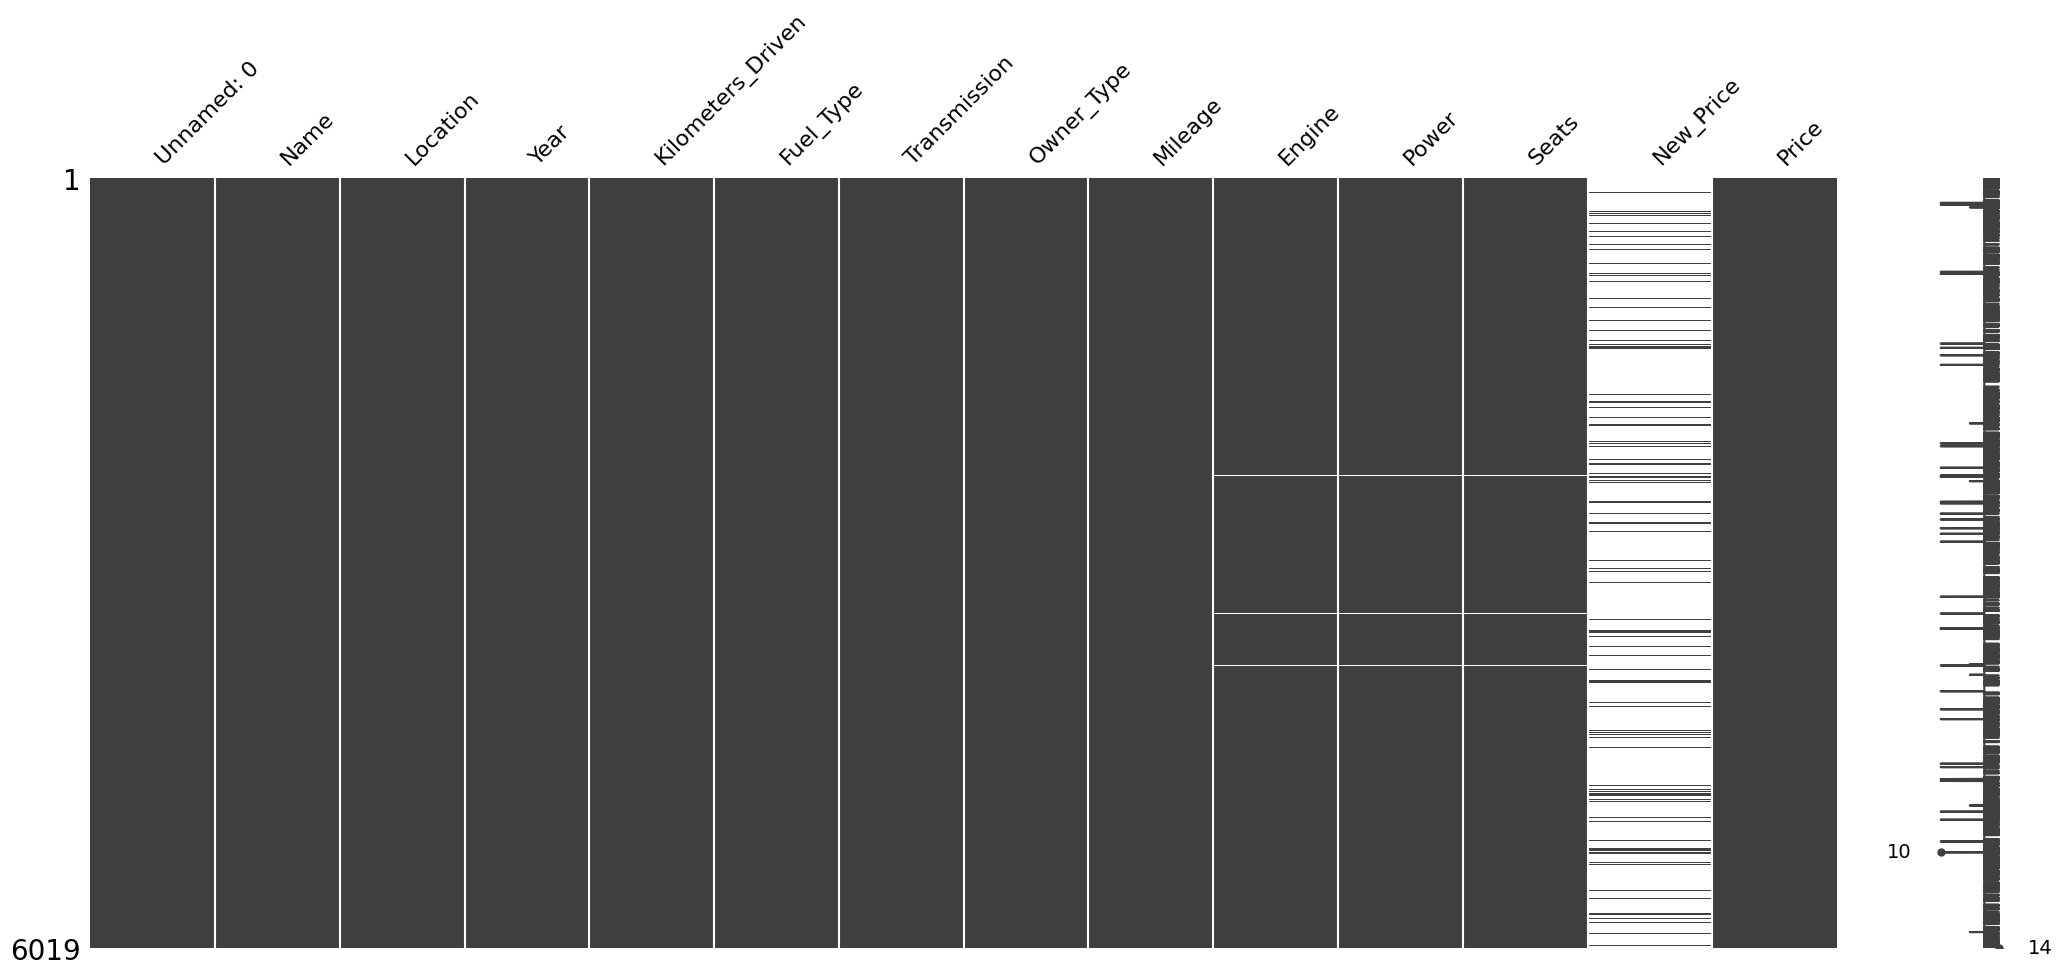

In [11]:
import missingno as msno

msno.matrix(df)
plt.show()

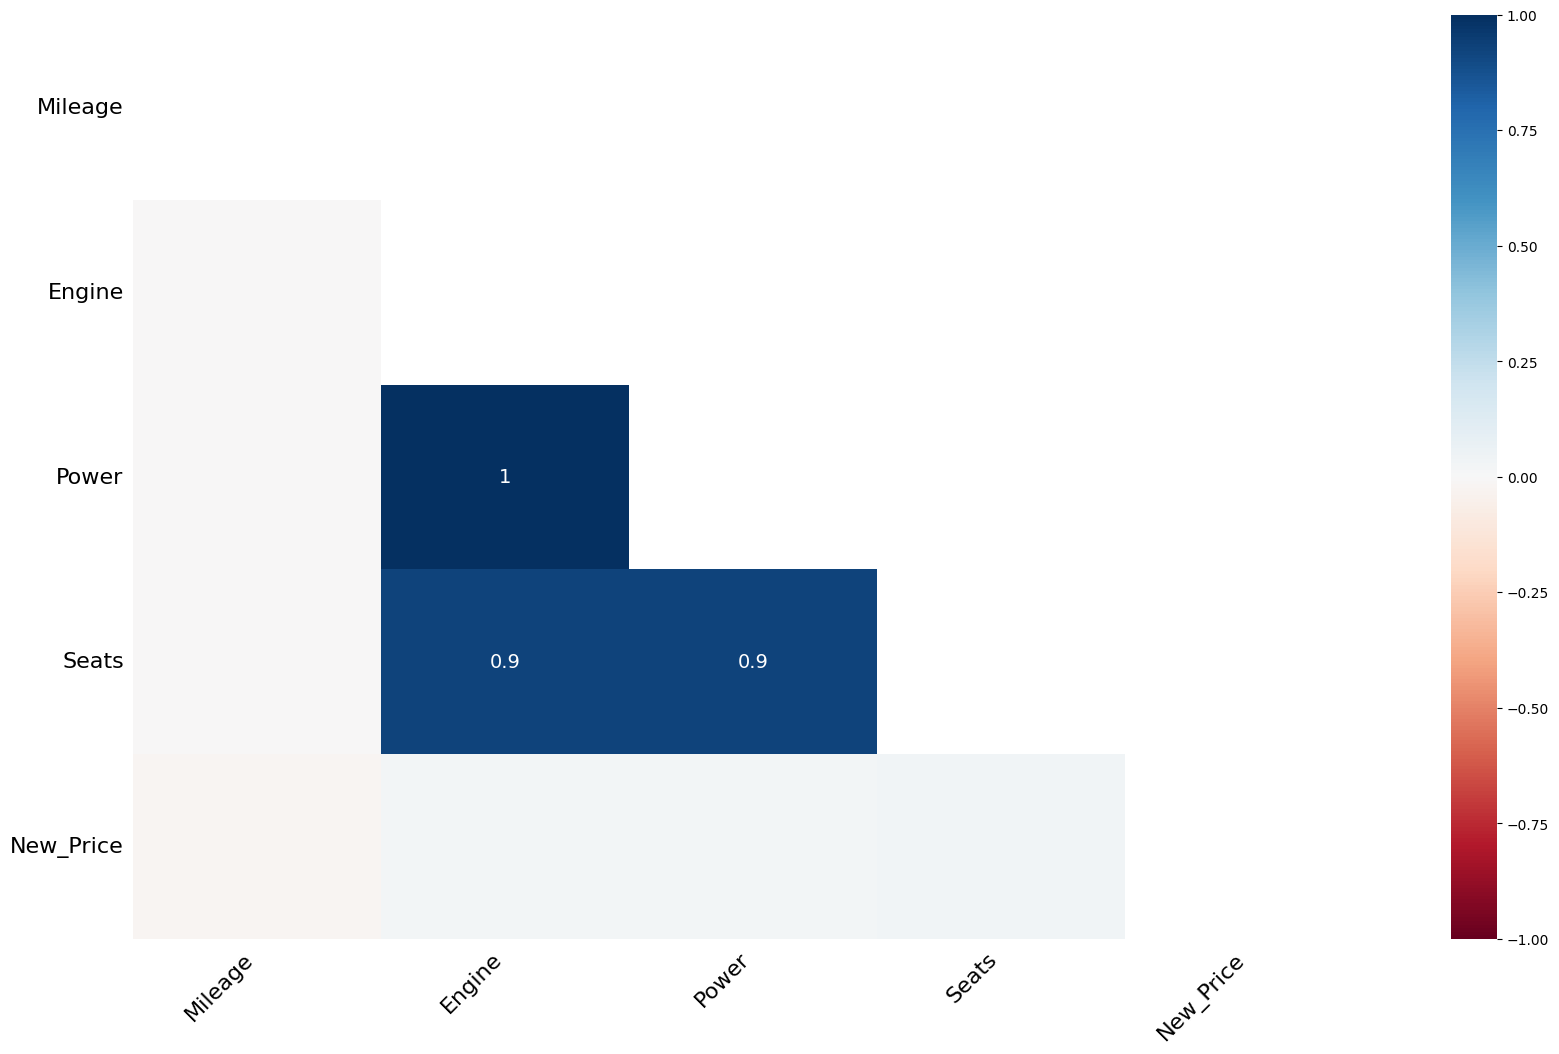

In [12]:
msno.heatmap(df)
plt.show()

## Checking for hidden null values

In [13]:
df.astype(str).apply(lambda x: x.str.contains('null')).sum()

Unnamed: 0             0
Name                   0
Location               0
Year                   0
Kilometers_Driven      0
Fuel_Type              0
Transmission           0
Owner_Type             0
Mileage                0
Engine                 0
Power                107
Seats                  0
New_Price              0
Price                  0
dtype: int64

In [14]:
(df['Mileage'].str.split(' ').str[0] == '0.0').sum()  # Mileage with 0 values

np.int64(68)

In [15]:
(df['Seats'] == 0).sum()  # Seats with 0 values

np.int64(1)

## Cleaning & Feature Engineering

In [16]:
df = df.drop(columns=["Unnamed: 0", "New_Price"])
df.shape

(6019, 12)

### Name

In [17]:
def get_brand(name):
    name = name.strip()
    if name.startswith('Land Rover'):
        return 'Land Rover'
    return name.split(' ')[0]

In [18]:
def get_model(name):
    name = name.strip()
    if name.startswith('Land Rover Range Rover'):
        return 'Range Rover'
    elif name.startswith('Land Rover'):
        return name.split(' ')[2]
    else:
        return name.split(' ')[1]

In [19]:
df['Brand'] = df['Name'].apply(get_brand).replace({'ISUZU': 'Isuzu'})
df['Model'] = df['Name'].apply(get_model)

In [20]:
df[['Name', 'Brand', 'Model']].head()

,Name,Brand,Model
0,Maruti Wagon R LXI CNG,Maruti,Wagon
1,Hyundai Creta 1.6 CRDi SX Option,Hyundai,Creta
2,Honda Jazz V,Honda,Jazz
3,Maruti Ertiga VDI,Maruti,Ertiga
4,Audi A4 New 2.0 TDI Multitronic,Audi,A4


mini cooper won't be treated like range rover.

mini is a brand, cooper is one of the models

In [21]:
df[df['Name'].str.startswith('Mini')]['Name'].unique() # mini will 

array(['Mini Countryman Cooper D', 'Mini Cooper Convertible S',
       'Mini Clubman Cooper S', 'Mini Cooper Convertible 1.6',
       'Mini Cooper 5 DOOR D', 'Mini Cooper S',
       'Mini Cooper Countryman D', 'Mini Cooper 3 DOOR D',
       'Mini Cooper Countryman D High', 'Mini Cooper 3 DOOR S',
       'Mini Cooper S Carbon Edition'], dtype=object)

In [22]:
df = df.drop(columns=['Name'])

### Engine

In [23]:
print(df.Engine.str.split(' ').str[1].unique())
df.Engine.sample(10, random_state=0)

['CC' nan]


5150    2179 CC
2164    1248 CC
1136    1598 CC
5641    2953 CC
1515    2494 CC
1675    1198 CC
2268    1499 CC
143     1086 CC
4646     998 CC
5008    1120 CC
Name: Engine, dtype: object

In [24]:
df['Engine'] = pd.to_numeric(df['Engine'].str.split(' ').str[0], errors='coerce')
df['Engine'].isna().sum()

np.int64(36)

### Power

In [25]:
print(df.Power.str.split(' ').str[1].unique())
df.Power.sample(10, random_state=0)

['bhp' nan]


5150       140 bhp
2164      null bhp
1136     103.6 bhp
5641    153.86 bhp
1515     100.6 bhp
1675      86.8 bhp
2268       110 bhp
143       null bhp
4646     67.04 bhp
5008        70 bhp
Name: Power, dtype: object

In [26]:
df['Power'] = pd.to_numeric(df['Power'].str.split(' ').str[0], errors='coerce')
df['Power'].isna().sum()

np.int64(143)

### Mileage

In [27]:
df['Mileage'].str.split(' ').str[1].unique()  # Mileage units

array(['km/kg', 'kmpl', nan], dtype=object)

CNG & LPG -> km/kg

diesel & petrol -> kmpl

electric -> NAN (2 missing mileage)

In [28]:
def convert_mileage(row):
    val = row['Mileage']
    if pd.isna(val):
        return np.nan
    
    num = float(val.split(' ')[0])
    unit = val.split(' ')[1]
    
    if (unit == 'km/kg') and (row['Fuel_Type'] == 'CNG'):
        return num / 1.40
    elif (unit == 'km/kg') and (row['Fuel_Type'] == 'LPG'):
        return num / 1.25
    else:
        return num

df['Mileage'] = df.apply(convert_mileage, axis=1) 
df['Mileage'].describe()

count    6017.000000
mean       18.060928
std         4.509207
min         0.000000
25%        15.100000
50%        18.120000
75%        21.020000
max        28.400000
Name: Mileage, dtype: float64

In [29]:
print((df['Mileage'] == 0).sum())
print((df['Seats'] == 0).sum())

68
1


In [30]:
df.loc[df["Mileage"] == 0, "Mileage"] = np.nan
df.loc[df["Seats"] == 0, "Seats"] = np.nan
df[["Mileage", "Seats"]].isna().sum()

Mileage    70
Seats      43
dtype: int64

### Fuel type

In [31]:
df[df['Fuel_Type'] == 'Electric']

,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,Price,Brand,Model
4446,Chennai,2016,50000,Electric,Automatic,First,NaN,72.0,41.0,5.0,13.00,Mahindra,E
4904,Mumbai,2011,44000,Electric,Automatic,First,NaN,1798.0,73.0,5.0,12.75,Toyota,Prius


In [32]:
df.loc[(df['Fuel_Type'] == 'Electric') & (df['Model'] == 'Prius'), 'Fuel_Type'] = 'Petrol'

In [33]:
df = df[df['Fuel_Type'] != 'Electric']

In [34]:
df['Fuel_Type'].value_counts()

Fuel_Type
Diesel    3205
Petrol    2747
CNG         56
LPG         10
Name: count, dtype: int64

### Year

In [35]:
df["Car_Age"] = 2019 - df["Year"]
df = df.drop(columns=["Year"])
df["Car_Age"].describe()

count    6018.000000
mean        5.642240
std         3.269836
min         0.000000
25%         3.000000
50%         5.000000
75%         8.000000
max        21.000000
Name: Car_Age, dtype: float64

### Impossible Values

In [36]:
df[(df['Price'] >= 120) | (df['Kilometers_Driven'] >= 6000000)]

,Location,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,Price,Brand,Model,Car_Age
2328,Chennai,6500000,Diesel,Automatic,First,15.97,2993.0,258.0,5.0,65.0,BMW,X5,2
4079,Hyderabad,25000,Diesel,Automatic,First,13.33,2993.0,255.0,5.0,160.0,Land Rover,Range Rover,2
5781,Delhi,6500,Petrol,Automatic,Third,6.40,5204.0,560.0,2.0,120.0,Lamborghini,Gallardo,8


In [37]:
df = df[(df['Price'] < 120) & (df['Kilometers_Driven'] < 6000000)]
df.shape

(6015, 13)

### New Duplicates

In [38]:
df.duplicated().sum()

np.int64(2)

In [39]:
df[df.duplicated(keep=False)]

,Location,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,Price,Brand,Model,Car_Age
942,Kolkata,29000,Diesel,Manual,First,27.39,1248.0,74.0,5.0,6.50,Maruti,Baleno,3
2940,Kolkata,29000,Diesel,Manual,First,27.39,1248.0,74.0,5.0,6.50,Maruti,Baleno,3
3623,Hyderabad,52195,Petrol,Manual,First,19.70,796.0,46.3,5.0,1.75,Maruti,Alto,12
4781,Hyderabad,52195,Petrol,Manual,First,19.70,796.0,46.3,5.0,1.75,Maruti,Alto,12


In [40]:
df = df.drop_duplicates()
df.duplicated().sum()

np.int64(0)

In [41]:
df.shape

(6013, 13)

## Save the cleaned dataset to a new CSV file

In [43]:
df.to_csv("../../datasets/a_regression_car_price/cleaned_car_prices.csv", index=False)
